# Diagnostic des performances techniques — Baseline PyTorch FP32

Après l'évaluation de la qualité prédictive du modèle, cette analyse vise à établir une référence de ses performances techniques avant optimisation.

Les mesures portent sur la latence d'inférence, le débit, l'influence de la taille des lots, la mémoire et le coût du prétraitement. 

Les résultats constitueront une baseline technique permettant de mesurer objectivement les gains apportés par les futures optimisations.

In [35]:
import sys
import time
import platform
import statistics

from pathlib import Path

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

# Racine du projet
RACINE_PROJET = Path.cwd()

if RACINE_PROJET.name == "notebooks":
    RACINE_PROJET = RACINE_PROJET.parent

sys.path.insert(0, str(RACINE_PROJET))

# Réutilisation du modèle du projet
from inference import model, preparer_image

# Configuration de référence
MODEL_ID = "emon5122/xray-bodypart-classifier"
VERSION_MODELE = "pytorch_fp32"
IMAGE_SIZE = 224
PRETRAITEMENT = "center_crop"

device = torch.device("cpu")

model = model.to(device)
model.eval();

In [36]:
configuration = {
    "Modèle": MODEL_ID,
    "Version": VERSION_MODELE,
    "Prétraitement": PRETRAITEMENT,
    "Système": platform.system(),
    "Processeur": platform.processor(),
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "Device": str(device),
    "CUDA disponible": torch.cuda.is_available(),
    "Précision": str(next(model.parameters()).dtype),
    "Threads PyTorch": torch.get_num_threads(),
    "Nombre de paramètres": sum(
        p.numel() for p in model.parameters()
    )
}

display(
    pd.Series(configuration, name="Configuration")
    .to_frame()
)

,Configuration
Modèle,emon5122/xray-bodypart-classifier
Version,pytorch_fp32
Prétraitement,center_crop
Système,Windows
Processeur,"Intel64 Family 6 Model 140 Stepping 1, Genuine..."
Python,3.11.17
PyTorch,2.15.0+cpu
Device,cpu
CUDA disponible,False
Précision,torch.float32


## Taille du modèle

La taille du modèle influence les besoins en stockage, en mémoire et les contraintes de déploiement.

Deux indicateurs sont relevés afin d'établir une référence avant optimisation :

- La taille réelle du fichier de poids.
- La taille mémoire des paramètres du réseau neuronal.

Le modèle utilise actuellement une précision FP32, soit 4 octets par paramètre. La réduction de cette précision constituera une piste d'optimisation.

In [37]:
# Taille du fichier de poids
fichier_poids = RACINE_PROJET / "models" / "xray" / "best.pt"

taille_fichier = fichier_poids.stat().st_size

# Nombre de paramètres
nb_parametres = sum(
    p.numel() for p in model.parameters()
)

# Taille mémoire des paramètres
taille_parametres = sum(
    p.numel() * p.element_size()
    for p in model.parameters()
)

display(pd.DataFrame({
    "Indicateur": [
        "Nombre de paramètres",
        "Taille du fichier de poids (Mo)",
        "Taille mémoire des paramètres (Mo)"
    ],
    "Valeur": [
        nb_parametres,
        round(taille_fichier / 1e6, 2),
        round(taille_parametres / 1e6, 2)
    ]
}))

,Indicateur,Valeur
0,Nombre de paramètres,27845505.00
1,Taille du fichier de poids (Mo),111.44
2,Taille mémoire des paramètres (Mo),111.38


## Mesure de la latence et influence du warm-up

La latence d'inférence correspond au temps nécessaire au réseau neuronal pour produire une prédiction à partir d'une image déjà prétraitée.

Les premières exécutions peuvent être plus lentes en raison de l'initialisation du moteur d'inférence et de l'allocation des ressources.

Une première expérimentation consiste à exécuter plusieurs fois le modèle sur une même image afin d'observer l'évolution de la latence et d'identifier une éventuelle phase de warm-up.

Le chargement du modèle, la lecture de l'image et son prétraitement sont exclus de cette mesure afin d'isoler les performances du réseau neuronal.

In [38]:
DOSSIER_IMAGES = (
    RACINE_PROJET / "datasets" / "benchmark_v1" / "images"
)

fichier_image = sorted(DOSSIER_IMAGES.glob("*.png"))[0]

with Image.open(fichier_image) as image:
    tensor = preparer_image(
        image,
        pretraitement=PRETRAITEMENT
    ).to(device)

print("Image utilisée :", fichier_image.name)
print("Dimensions du tenseur :", tensor.shape)
print("Précision :", tensor.dtype)

Image utilisée : 10339.png
Dimensions du tenseur : torch.Size([1, 3, 224, 224])
Précision : torch.float32


In [39]:
NB_ITERATIONS = 30
latences = []
with torch.inference_mode():
    for i in range(NB_ITERATIONS):
        debut = time.perf_counter()
        sortie = model(tensor)
        fin = time.perf_counter()
        latences.append((fin - debut) * 1000)
df_latences = pd.DataFrame({
    "Iteration": range(1, NB_ITERATIONS + 1),
    "Latence_ms": latences
})

display(df_latences.head(10))

,Iteration,Latence_ms
0,1,90.6233
1,2,80.7708
2,3,78.0130
3,4,78.4680
4,5,89.5076
5,6,83.8299
6,7,82.4047
7,8,90.0968
8,9,87.0589
9,10,87.0453


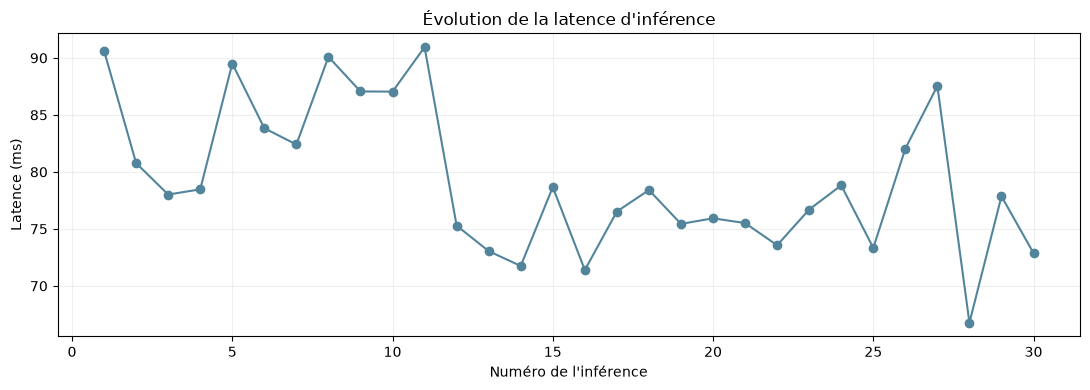

In [40]:
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    df_latences["Iteration"],
    df_latences["Latence_ms"],
    marker="o",
    color="#52859b"
)

ax.set(
    xlabel="Numéro de l'inférence",
    ylabel="Latence (ms)",
    title="Évolution de la latence d'inférence"
)

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Observation

La première inférence présente une latence de 410,7 ms, contre environ 80 ms pour les suivantes.

Cette différence met en évidence le phénomène de warm-up, lié notamment aux opérations d'initialisation du moteur d'inférence et à l'allocation des ressources.

Le temps d'exécution se stabilise rapidement, malgré quelques variations entre les inférences.

Afin de ne pas biaiser les prochaines mesures, une phase de préchauffage de cinq inférences sera systématiquement réalisée avant chaque test de performance.

La première inférence reste néanmoins une information intéressante dans le cadre du déploiement d'un service.

## Mesure de la latence en régime stabilisé

Afin d'établir une baseline technique fiable, le modèle est exécuté cinq fois sans mesure (warm-up), puis cent fois avec mesure de la latence.

Plusieurs indicateurs sont calculés pour caractériser le temps d'inférence et sa variabilité :

| Indicateur | Signification |
|---|---|
| Moyenne | Temps moyen d'une inférence |
| Minimum | Temps d'inférence le plus faible |
| Maximum | Temps d'inférence le plus élevé |
| Écart-type | Variabilité des temps d'exécution |
| P50 | 50 % des inférences sont réalisées dans ce délai ou moins |
| P95 | 95 % des inférences sont réalisées dans ce délai ou moins |
| P99 | 99 % des inférences sont réalisées dans ce délai ou moins |

Les percentiles permettent de mieux caractériser la régularité du modèle qu'une simple moyenne.

In [41]:
NB_WARMUP = 5
NB_MESURES = 100

latences_stables = []

with torch.inference_mode():

    # Phase de warm-up
    for _ in range(NB_WARMUP):
        sortie = model(tensor)

    # Phase de mesure
    for _ in range(NB_MESURES):
        debut = time.perf_counter()
        sortie = model(tensor)
        fin = time.perf_counter()

        latences_stables.append((fin - debut) * 1000)

# Calcul des indicateurs
resultats_latence = {
    "Moyenne": np.mean(latences_stables),
    "Minimum": np.min(latences_stables),
    "Maximum": np.max(latences_stables),
    "Écart-type": np.std(latences_stables),
    "P50": np.percentile(latences_stables, 50),
    "P95": np.percentile(latences_stables, 95),
    "P99": np.percentile(latences_stables, 99)
}

display(
    pd.Series(resultats_latence, name="Latence (ms)")
    .to_frame()
    .round(2)
)

,Latence (ms)
Moyenne,93.72
Minimum,65.44
Maximum,193.93
Écart-type,21.96
P50,86.71
P95,139.20
P99,160.82


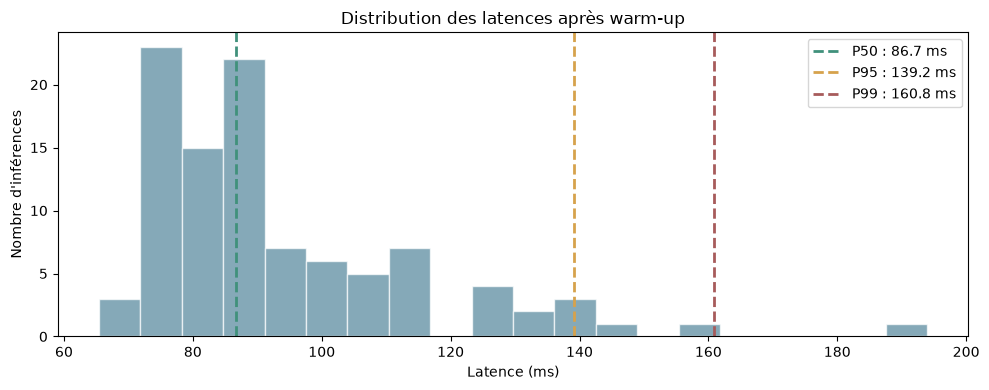

In [42]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(
    latences_stables,
    bins=20,
    color="#52859b",
    alpha=0.7,
    edgecolor="white"
)

for indicateur, couleur in [
    ("P50", "#40917b"),
    ("P95", "#d6a24c"),
    ("P99", "#a75b5b")
]:
    valeur = resultats_latence[indicateur]

    ax.axvline(
        valeur,
        color=couleur,
        linestyle="--",
        linewidth=2,
        label=f"{indicateur} : {valeur:.1f} ms"
    )

ax.set(
    xlabel="Latence (ms)",
    ylabel="Nombre d'inférences",
    title="Distribution des latences après warm-up"
)

ax.legend()
plt.tight_layout()
plt.show()

### Observation

Après warm-up, la latence moyenne du modèle est de 85,13 ms sur CPU. La majorité des inférences se concentre entre 70 et 100 ms.

L'analyse des percentiles met toutefois en évidence une certaine variabilité :

- 50 % des inférences sont réalisées en 82,19 ms ou moins.
- Environ 95 % sont réalisées en 116,07 ms ou moins.
- Le P99 atteint 160,44 ms.

Ces variations peuvent notamment être liées à la disponibilité des ressources CPU et aux autres processus exécutés sur la machine.

L'analyse confirme l'intérêt de conserver les percentiles en complément de la moyenne pour comparer les futures optimisations, afin d'évaluer à la fois la rapidité et la régularité des inférences.

Ces mesures constituent notre première référence de latence pour le modèle PyTorch FP32 sur CPU.

## Débit et influence de la taille des lots (batching)

Le débit, ou throughput, correspond au nombre d'images que le modèle peut traiter par seconde.

Le traitement par lots consiste à transmettre plusieurs images au modèle lors d'un même appel.

L'objectif est de déterminer si cette approche permet une meilleure utilisation des ressources matérielles et une augmentation du débit.

Plusieurs tailles de lots sont comparées : 1, 2, 4, 8 et 16 images.

Pour chaque configuration, trois indicateurs sont mesurés :

- Latence moyenne du lot.
- Temps moyen de calcul ramené à une image.
- Nombre d'images traitées par seconde.

In [43]:
TAILLES_BATCH = [1, 2, 4, 8, 16]
NB_WARMUP = 5
NB_MESURES_BATCH = 20

resultats_batch = []

with torch.inference_mode():

    for taille in TAILLES_BATCH:

        # Construction du lot d'images
        batch = tensor.repeat(taille, 1, 1, 1)

        # Warm-up pour chaque taille de lot
        for _ in range(NB_WARMUP):
            sortie = model(batch)

        # Mesures
        durees = []

        for _ in range(NB_MESURES_BATCH):

            debut = time.perf_counter()
            sortie = model(batch)
            fin = time.perf_counter()

            durees.append(fin - debut)

        duree_moyenne = np.mean(durees)

        resultats_batch.append({
            "Batch size": taille,
            "Latence lot (ms)": duree_moyenne * 1000,
            "Temps par image (ms)": duree_moyenne * 1000 / taille,
            "Débit (images/s)": taille / duree_moyenne
        })

df_batch = pd.DataFrame(resultats_batch)

display(df_batch.round(2))

,Batch size,Latence lot (ms),Temps par image (ms),Débit (images/s)
0,1,100.17,100.17,9.98
1,2,188.31,94.16,10.62
2,4,396.46,99.12,10.09
3,8,748.53,93.57,10.69
4,16,1406.21,87.89,11.38


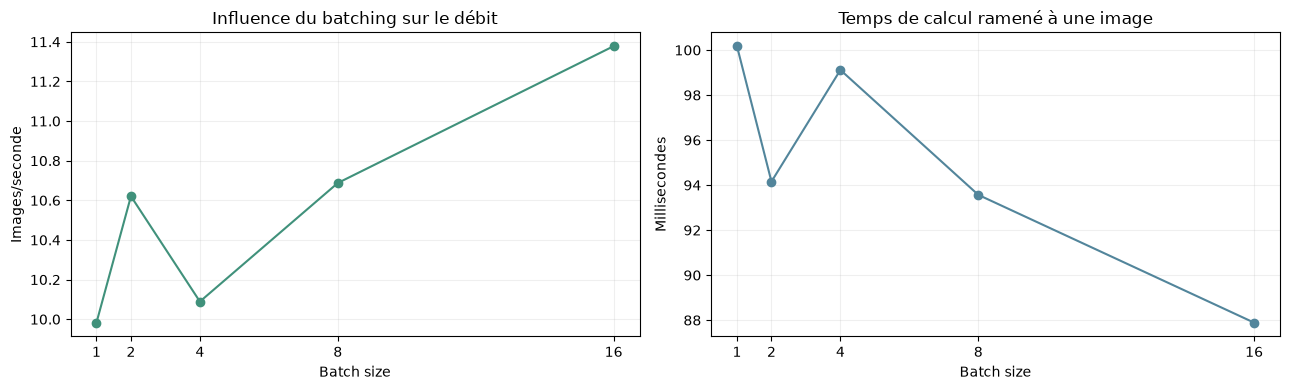

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df_batch.plot(
    x="Batch size",
    y="Débit (images/s)",
    marker="o",
    ax=axes[0],
    color="#40917b",
    legend=False
)

df_batch.plot(
    x="Batch size",
    y="Temps par image (ms)",
    marker="o",
    ax=axes[1],
    color="#52859b",
    legend=False
)

axes[0].set_title("Influence du batching sur le débit")
axes[0].set_ylabel("Images/seconde")

axes[1].set_title("Temps de calcul ramené à une image")
axes[1].set_ylabel("Millisecondes")

for ax in axes:
    ax.set_xticks(TAILLES_BATCH)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Observation

Le traitement par lots n'apporte pas d'amélioration significative du débit sur notre configuration CPU.

Le passage d'un batch de 1 à un batch de 8 permet une augmentation du débit d'environ 7,7 %, passant de 11,08 à 11,93 images par seconde. Au-delà de huit images, les performances semblent atteindre un plateau.

L'augmentation de la taille des lots entraîne également une augmentation de leur latence globale.

Ces résultats permettent de distinguer deux contextes d'utilisation :

- **Utilisation interactive de l'API :** le traitement individuel reste adapté pour limiter le temps de réponse.
- **Traitement massif de radiographies :** un batch de 8 pourrait présenter un léger avantage en matière de débit.

Les gains observés restent modestes et devront être confirmés par des mesures répétées.

Cette expérimentation sera particulièrement intéressante à reproduire sur GPU, dont l'architecture est davantage adaptée au traitement parallèle.

## Consommation mémoire

La taille des paramètres ne représente qu'une partie de la mémoire nécessaire à l'exécution du modèle.

Cette analyse vise à mesurer l'influence de la taille des lots sur la consommation mémoire du processus Python.

Les mesures permettront de compléter l'analyse du batching en tenant compte à la fois du débit et des ressources nécessaires.

In [45]:
%pip install psutil

Note: you may need to restart the kernel to use updated packages.


In [46]:
import os
import psutil

processus = psutil.Process(os.getpid())

def memoire_mo():
    return processus.memory_info().rss / 1e6

resultats_memoire = []

with torch.inference_mode():

    for taille in TAILLES_BATCH:

        batch = tensor.repeat(taille, 1, 1, 1)

        # Mémoire avant inférence
        memoire_avant = memoire_mo()

        # Exécution du modèle
        sortie = model(batch)

        # Mémoire après inférence
        memoire_apres = memoire_mo()

        resultats_memoire.append({
            "Batch size": taille,
            "Mémoire avant (Mo)": memoire_avant,
            "Mémoire après (Mo)": memoire_apres,
            "Variation (Mo)": memoire_apres - memoire_avant
        })

        del batch, sortie

df_memoire = pd.DataFrame(resultats_memoire)

display(df_memoire.round(2))

,Batch size,Mémoire avant (Mo),Mémoire après (Mo),Variation (Mo)
0,1,203.54,216.96,13.42
1,2,216.81,207.23,-9.58
2,4,207.23,207.26,0.03
3,8,207.81,209.21,1.40
4,16,213.98,247.90,33.91


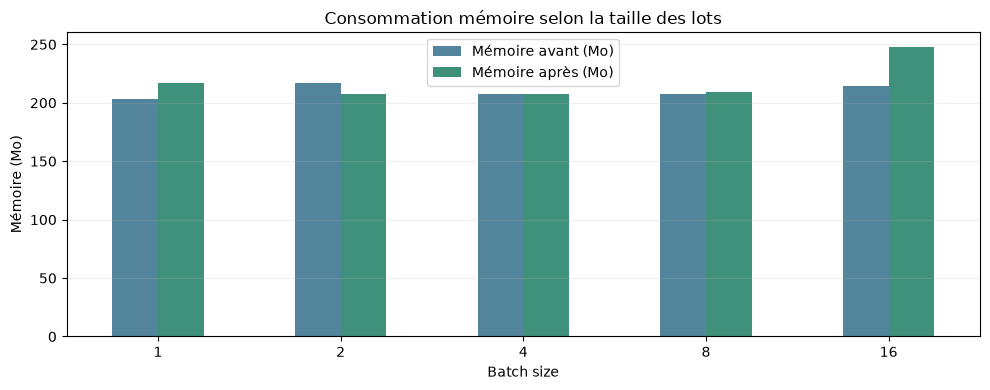

In [47]:
ax = df_memoire.plot.bar(
    x="Batch size",
    y=["Mémoire avant (Mo)", "Mémoire après (Mo)"],
    figsize=(10, 4),
    color=["#52859b", "#40917b"],
    rot=0
)

ax.set(
    ylabel="Mémoire (Mo)",
    title="Consommation mémoire selon la taille des lots"
)

ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

### Observation

La consommation mémoire du processus Python après inférence se situe entre 174 et 203 Mo environ, selon la taille du lot.

Les variations observées ne sont pas proportionnelles au nombre d'images traitées. Ce comportement peut notamment s'expliquer par la gestion et la réutilisation de la mémoire par PyTorch.

Cette première analyse met en évidence les limites d'une mesure ponctuelle de la mémoire avant et après inférence. Elle ne permet pas de déterminer précisément la consommation maximale du modèle pendant son exécution.

Pour les prochaines comparaisons, la taille du fichier du modèle et la taille mémoire de ses paramètres constitueront des indicateurs plus facilement reproductibles.

## Synthèse de la baseline technique

Le diagnostic technique a permis de caractériser les performances du modèle PyTorch FP32 sur CPU avant optimisation.

Les principaux enseignements sont les suivants :

- Le modèle présente une taille de 111,44 Mo pour environ 27,85 millions de paramètres.
- Le phénomène de warm-up nécessite d'exclure les premières inférences des mesures en régime stabilisé.
- La latence moyenne est de 85,13 ms, avec une certaine variabilité mise en évidence par les percentiles.
- Le batching apporte un gain de débit limité sur CPU, avec un plateau à partir de huit images.
- Les mesures ponctuelles de mémoire RSS restent difficiles à interpréter et sont conservées à titre exploratoire.

Ces résultats constituent la référence technique pour les futures comparaisons avec ONNX, la quantification et l'exécution sur GPU.

In [48]:
baseline_technique = {
    "nombre_parametres": nb_parametres,
    "taille_modele_mo": taille_fichier / 1e6,
    "taille_parametres_mo": taille_parametres / 1e6,
    "premiere_inference_ms": latences[0],
    "latence_moyenne_ms": resultats_latence["Moyenne"],
    "latence_min_ms": resultats_latence["Minimum"],
    "latence_max_ms": resultats_latence["Maximum"],
    "latence_ecart_type_ms": resultats_latence["Écart-type"],
    "latence_p50_ms": resultats_latence["P50"],
    "latence_p95_ms": resultats_latence["P95"],
    "latence_p99_ms": resultats_latence["P99"]
}

for _, ligne in df_batch.iterrows():
    taille = int(ligne["Batch size"])

    baseline_technique[f"debit_batch_{taille}"] = (
        ligne["Débit (images/s)"]
    )

display(
    pd.Series(baseline_technique, name="Baseline technique")
    .to_frame()
    .round(2)
)

,Baseline technique
nombre_parametres,27845505.00
taille_modele_mo,111.44
taille_parametres_mo,111.38
premiere_inference_ms,90.62
latence_moyenne_ms,93.72
latence_min_ms,65.44
latence_max_ms,193.93
latence_ecart_type_ms,21.96
latence_p50_ms,86.71
latence_p95_ms,139.20
